In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.api import qqplot

In [3]:
# Import Data
df = pd.read_csv("../data/bangkok_dengue_1993_2023.csv")

# Format to datetime
df["calendar_start_date"] = pd.to_datetime(df["calendar_start_date"])
df["calendar_end_date"] = pd.to_datetime(df["calendar_end_date"])
df = df.sort_values("calendar_start_date")

**Using time series models to forecast Dengue cases in Bankok, Thailand.**

This jupyter notebook analyzes historical data of Dengue cases in Bangkok to fit two candidate ARIMA models, which can then be used for making forecasts, providing a parsimonious albiet less informed alternative to more computationally expensive MCMC and machine learning models. The other drawback to this method is that the frequentist uncertainty quantification, which is less inforamtive than a Bayesian approach. 

We'll first take a look at the data we're dealing with:

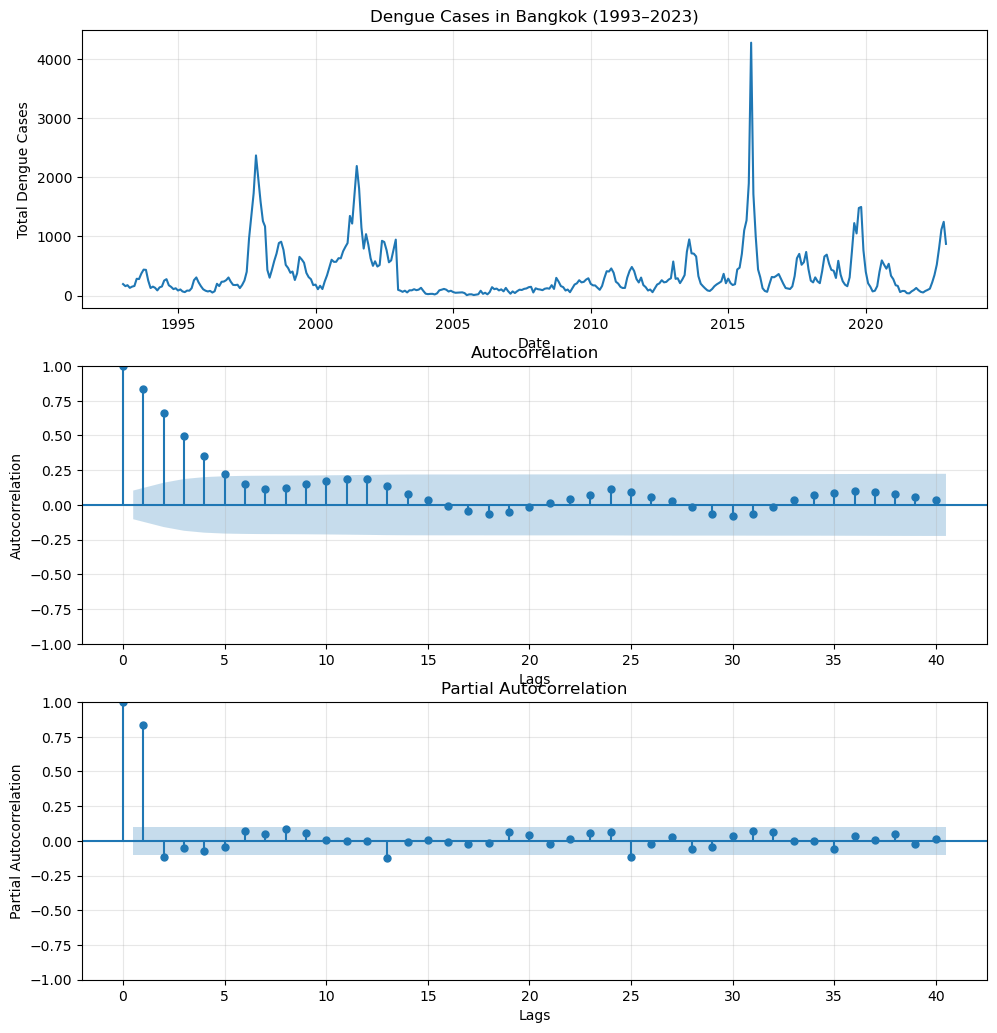

In [4]:
fig = plt.figure(figsize=(10,10))


ax1 = fig.add_subplot(311)
plt.plot(df["calendar_start_date"], df["dengue_total"])
plt.xlabel("Date")
plt.ylabel("Total Dengue Cases")
plt.title("Dengue Cases in Bangkok (1993–2023)")

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.grid(True, alpha=0.3)
plt.tight_layout()

ax2 = fig.add_subplot(312)
plot_acf(df["dengue_total"].dropna(), lags=40, ax=ax2)
plt.xlabel("Lags")
plt.ylabel("Autocorrelation")
plt.grid(True, alpha=0.3)

ax3 = fig.add_subplot(313)
plot_pacf(df["dengue_total"].dropna(), lags=40, ax=ax3)
plt.xlabel("Lags")
plt.ylabel("Partial Autocorrelation")
plt.grid(True, alpha=0.3)
plt.show()


The above plot suggests a strong autocorrelation exhibiting geometric decay, suggesting that the process is not stationary.  The process also seems to have irregular variation, so it makes sense to take the log of the process. 

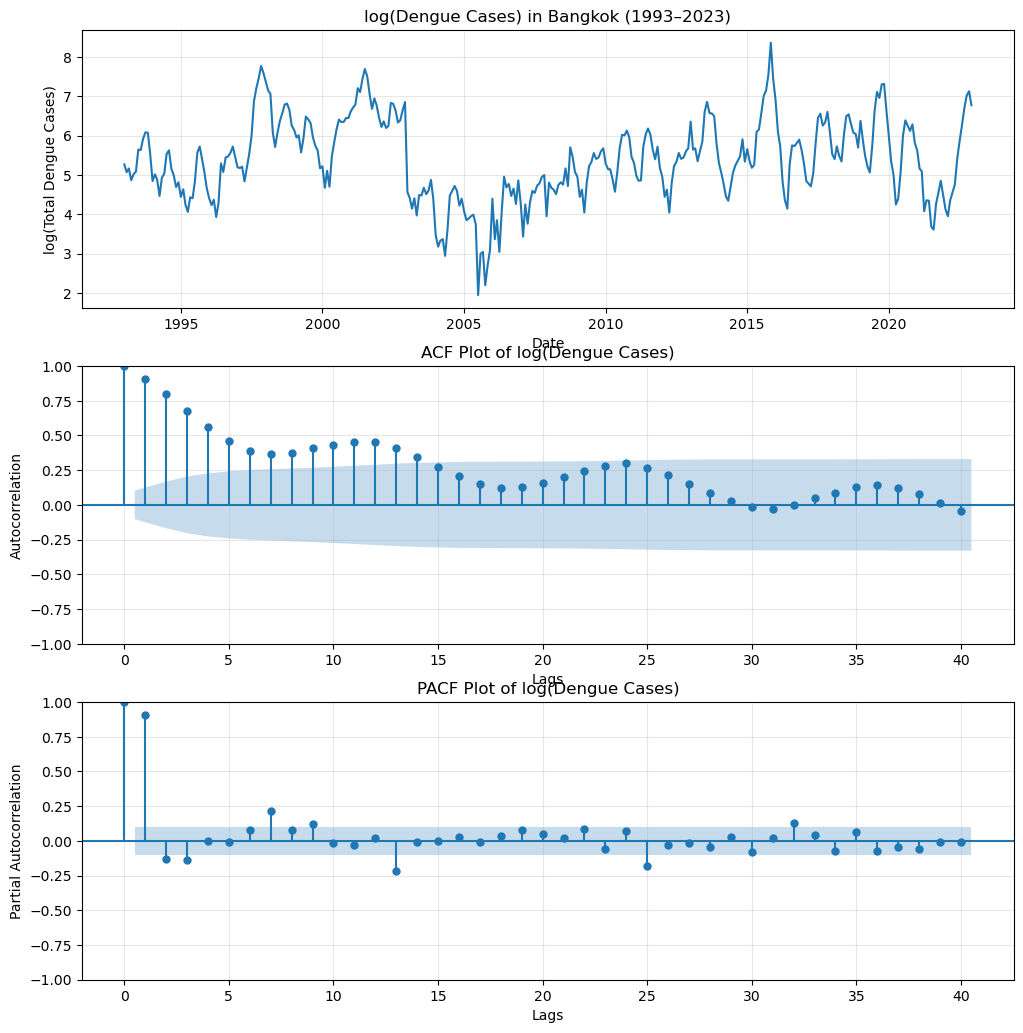

In [ ]:
fig = plt.figure(figsize=(10,10))

df["log_dengue_total"] = np.log(df["dengue_total"])

ax1 = fig.add_subplot(311)
plt.plot(df["calendar_start_date"], df["log_dengue_total"])
plt.xlabel("Date")
plt.ylabel("log(Total Dengue Cases)")
plt.title("log(Dengue Cases) in Bangkok (1993–2023)")

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.grid(True, alpha=0.3)
plt.tight_layout()

ax2 = fig.add_subplot(312)
plot_acf(df["log_dengue_total"].dropna(), lags=40, ax=ax2)

# 3. Customize and display
plt.xlabel("Lags")
plt.ylabel("Autocorrelation")
plt.grid(True, alpha=0.3)

ax3 = fig.add_subplot(313)
plot_pacf(df["log_dengue_total"].dropna(), lags=40, ax=ax3)

# 3. Customize and display
plt.xlabel("Lags")
plt.ylabel("Partial Autocorrelation")
plt.grid(True, alpha=0.3)
plt.show()

The log of the process has less irregular variation, but a quick look at the process itself as well as the geometric decay of the ACF suggests that the process is not stationary. However, the PACF plot suggests that an AR(1) (most likely), AR(2) or AR(3) model may be an appropriate candidate for a conservative model. 

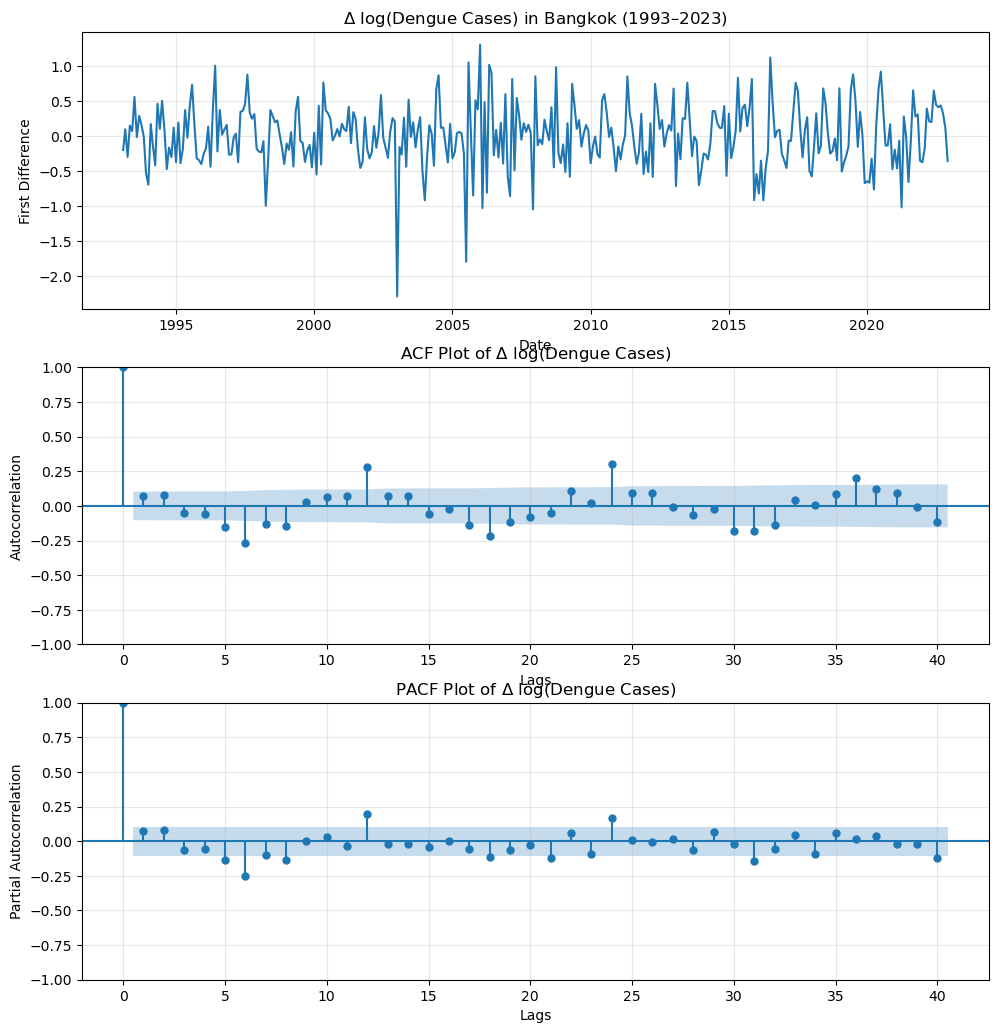

In [240]:
fig = plt.figure(figsize=(10,10))

df["first_diff"] = df["log_dengue_total"].diff()

ax1 = fig.add_subplot(311)
plt.plot(df["calendar_start_date"], df["first_diff"])
plt.xlabel("Date")
plt.ylabel("First Difference")
plt.title("$\Delta$ log(Dengue Cases) in Bangkok (1993–2023)")

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.grid(True, alpha=0.3)
plt.tight_layout()

ax2 = fig.add_subplot(312)
plot_acf(df["first_diff"].dropna(), lags=40, ax=ax2)

# 3. Customize and display
plt.title("ACF Plot of $\Delta$ log(Dengue Cases)")
plt.xlabel("Lags")
plt.ylabel("Autocorrelation")
plt.grid(True, alpha=0.3)

ax3 = fig.add_subplot(313)
plot_pacf(df["first_diff"].dropna(), lags=40, ax=ax3)

# 3. Customize and display
plt.title("PACF Plot of $\Delta$ log(Dengue Cases)")
plt.xlabel("Lags")
plt.ylabel("Partial Autocorrelation")
plt.grid(True, alpha=0.3)
plt.show()

No clear models are apparent from the above ACF/PACF plots, but the first order differencing seems to have dealt with the nonstationarity.  The consistently positive (partial)autocorrelation at lag 12 suggests that it may be useful to take a seasonal difference of order 12. 

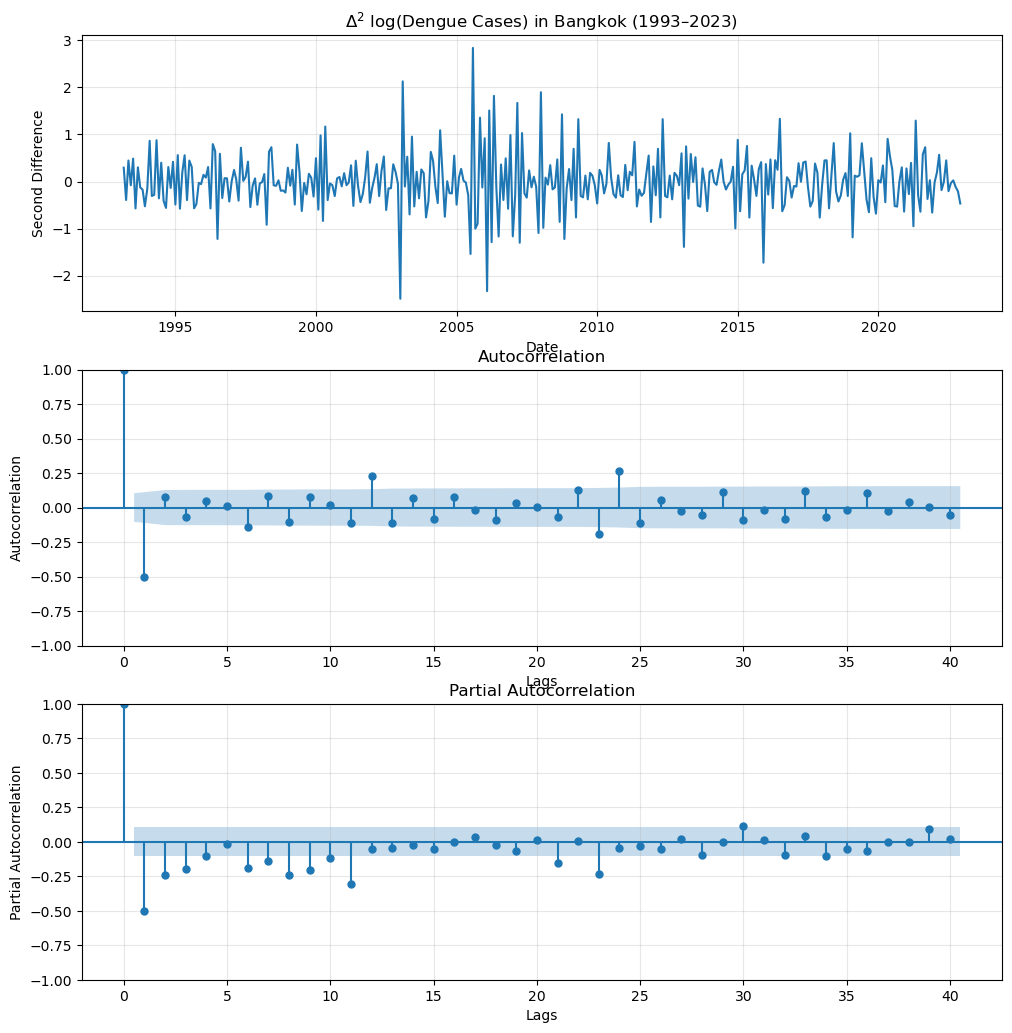

In [239]:
fig = plt.figure(figsize=(10,10))

df["second_diff"] = df["first_diff"].diff()

ax1 = fig.add_subplot(311)
plt.plot(df["calendar_start_date"], df["second_diff"])
plt.xlabel("Date")
plt.ylabel("Second Difference")
plt.title("$\Delta^2$ log(Dengue Cases) in Bangkok (1993–2023)")

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.grid(True, alpha=0.3)
plt.tight_layout()

ax2 = fig.add_subplot(312)
plot_acf(df["second_diff"].dropna(), lags=40, ax=ax2)

# 3. Customize and display
plt.xlabel("Lags")
plt.ylabel("Autocorrelation")
plt.grid(True, alpha=0.3)

ax3 = fig.add_subplot(313)
plot_pacf(df["second_diff"].dropna(), lags=40, ax=ax3)

# 3. Customize and display
plt.xlabel("Lags")
plt.ylabel("Partial Autocorrelation")
plt.grid(True, alpha=0.3)
plt.show()

This overdifferenced data shows a spurious correlation, suggesting that an ARIMA(0,2,1) may be appropriate, but in practice probably is not.  

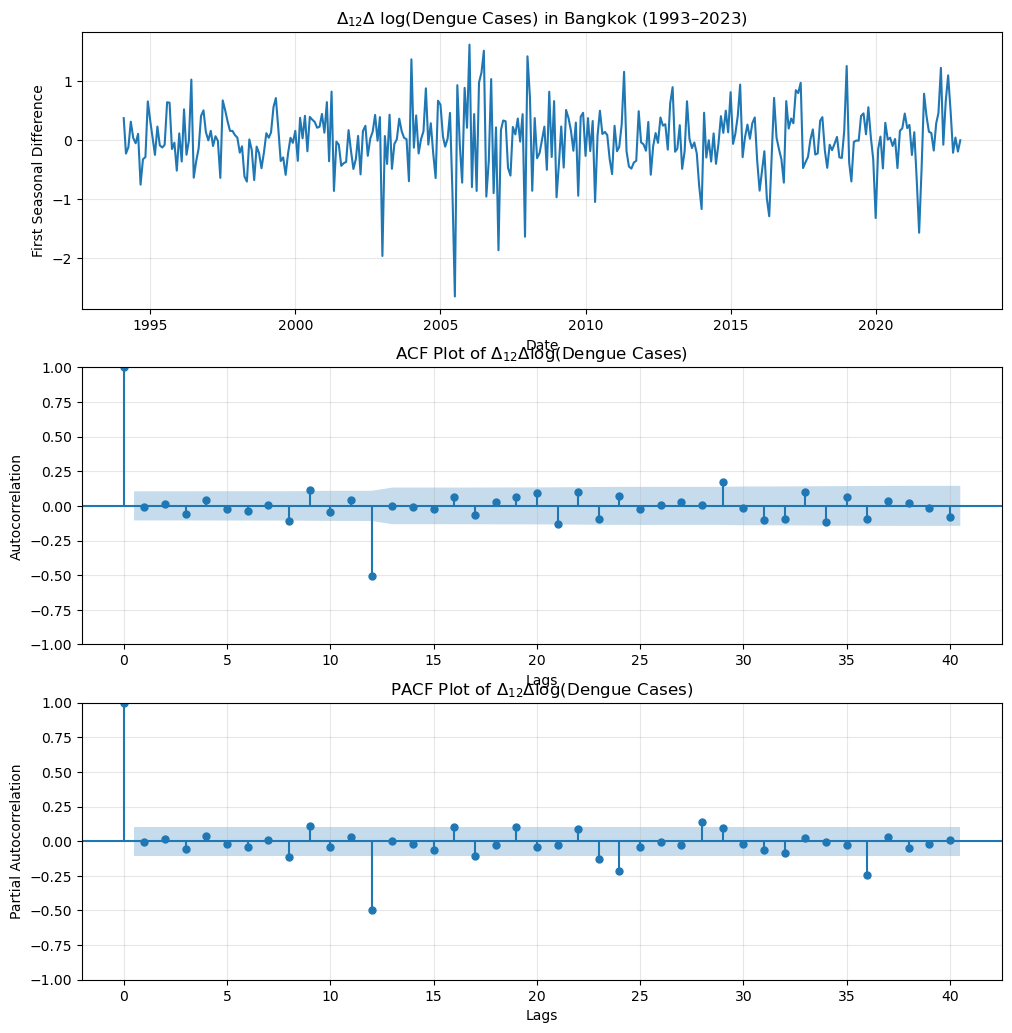

In [235]:
fig = plt.figure(figsize=(10,10))

df["first_seasonal_diff"] = df["first_diff"].diff(12)

ax1 = fig.add_subplot(311)
plt.plot(df["calendar_start_date"], df["first_seasonal_diff"])

plt.xlabel("Date")
plt.ylabel("First Seasonal Difference")
plt.title("$\Delta_{12} \Delta$ log(Dengue Cases) in Bangkok (1993–2023)")

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.grid(True, alpha=0.3)
plt.tight_layout()


ax2 = fig.add_subplot(312)
plot_acf(df["first_seasonal_diff"].dropna(), lags=40, ax=ax2)

# 3. Customize and display
plt.title("ACF Plot of $\Delta_{12} \Delta$log(Dengue Cases)")
plt.xlabel("Lags")
plt.ylabel("Autocorrelation")
plt.grid(True, alpha=0.3)

ax3 = fig.add_subplot(313)
plot_pacf(df["first_seasonal_diff"].dropna(), lags=40, ax=ax3)

# 3. Customize and display
plt.title("PACF Plot of $\Delta_{12} \Delta$log(Dengue Cases)")
plt.xlabel("Lags")
plt.ylabel("Partial Autocorrelation")
plt.grid(True, alpha=0.3)
plt.show()

The significan spike at lag 12 suggests that we could use SARIMA(0,1,0)x(1,1,0)_12 or SARIMA(0,1,0)x(0,1,1)_12

Model candidates: 

AR(1), AR(2), AR(3)

SARIMA(0,1,0)x(0,1,1)_12

SARIMA(0,1,0)x(1,1,0)_12

                               SARIMAX Results                                
Dep. Variable:       log_dengue_total   No. Observations:                  360
Model:                 ARIMA(1, 0, 0)   Log Likelihood                -209.719
Date:                Fri, 16 Oct 2026   AIC                            425.437
Time:                        15:27:05   BIC                            437.096
Sample:                             0   HQIC                           430.073
                                - 360                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          5.4093      0.262     20.669      0.000       4.896       5.922
ar.L1          0.9080      0.019     48.106      0.000       0.871       0.945
sigma2         0.1868      0.010     18.593      0.0

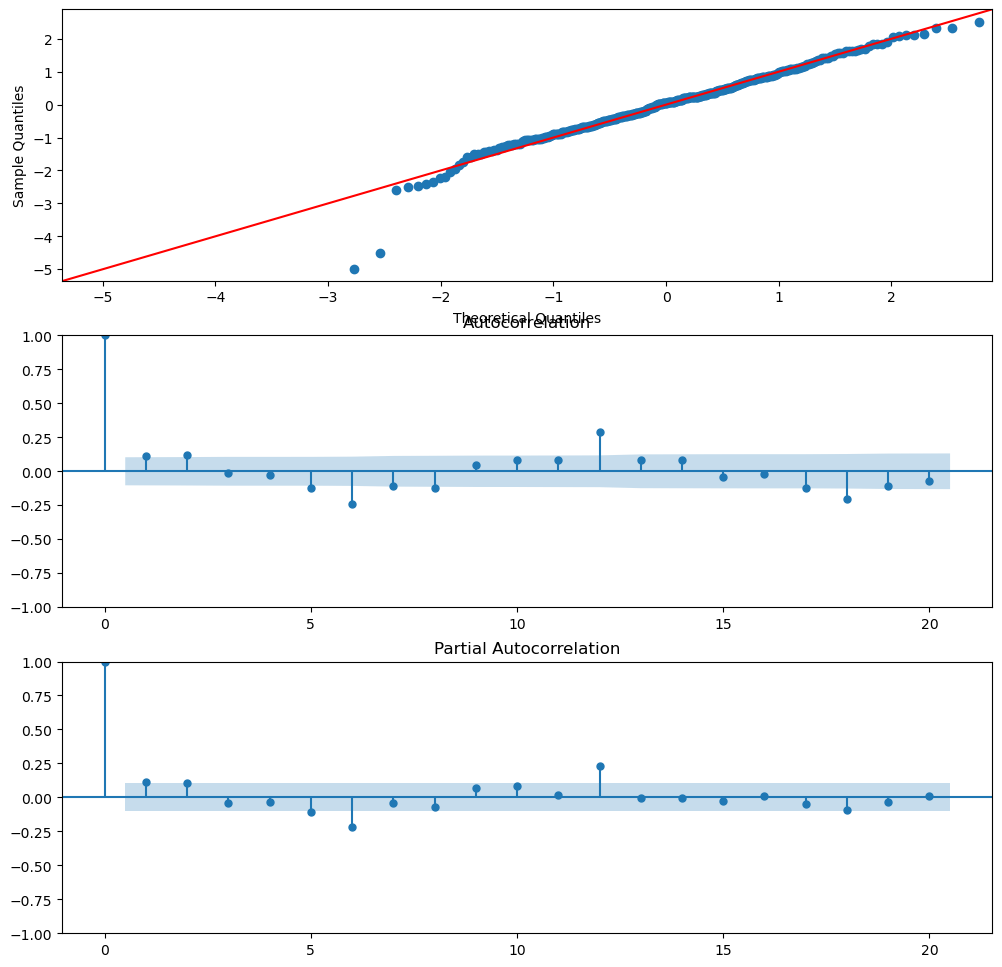

In [251]:
# AR(1) Model 
ar1_model = ARIMA(df["log_dengue_total"].dropna(), order=(1,0,0)).fit()
print(ar1_model.summary())

# Diagnostic Plots for AR(1) Model
fig = plt.figure(figsize=(12, 12))
ax1 = fig.add_subplot(311)
fig = qqplot(ar1_model.resid, line='45', ax=ax1, fit=True)
ax2 = fig.add_subplot(312)
fig = plot_acf(ar1_model.resid, lags=20, ax=ax2)
ax3 = fig.add_subplot(313)
fig = plot_pacf(ar1_model.resid, lags=20, ax=ax3)

                                     SARIMAX Results                                      
Dep. Variable:                   log_dengue_total   No. Observations:                  360
Model:             ARIMA(0, 1, 0)x(0, 1, [1], 12)   Log Likelihood                -177.083
Date:                            Fri, 16 Oct 2026   AIC                            358.166
Time:                                    15:20:54   BIC                            365.865
Sample:                                         0   HQIC                           361.231
                                            - 360                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.S.L12      -0.9427      0.041    -22.871      0.000      -1.023      -0.862
sigma2         0.1508      0.008   

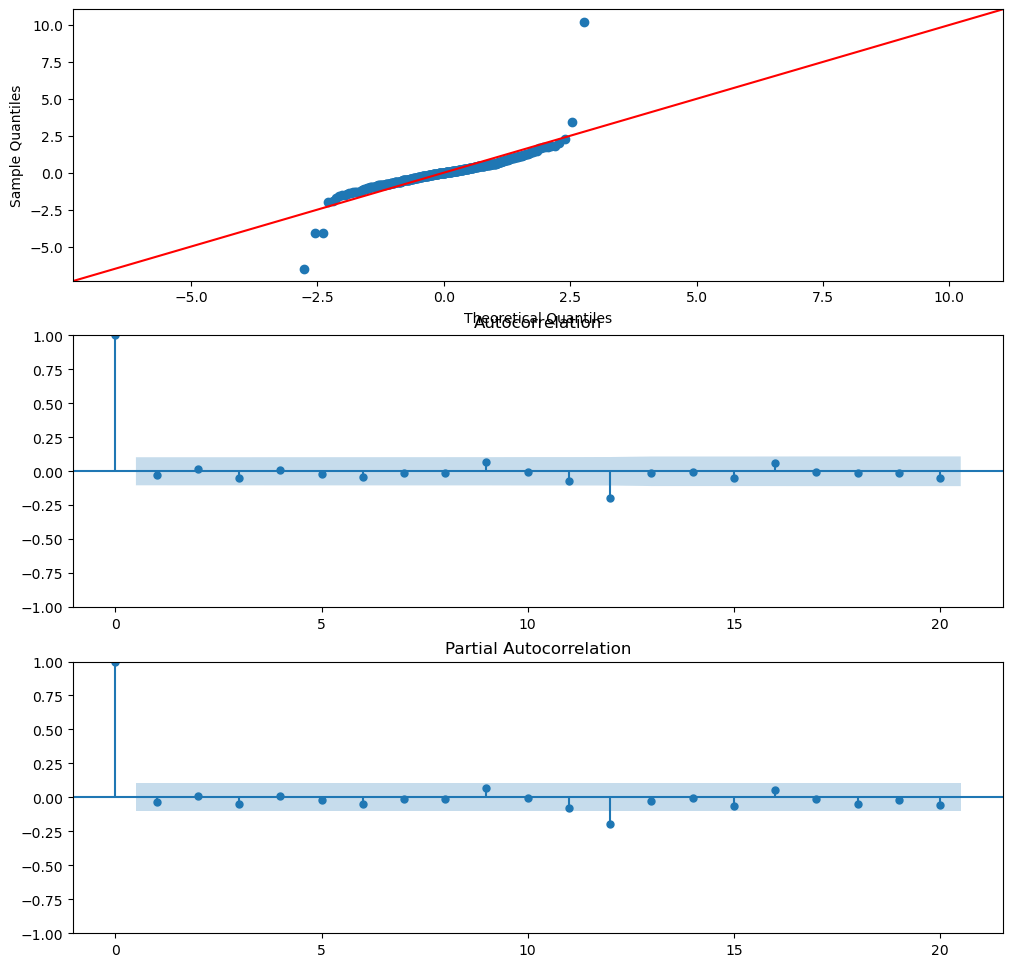

In [247]:
# SARIMA(0,1,0)x(0,1,1,12) Model
sarima_model = ARIMA(df["log_dengue_total"].dropna(), order=(0,1,0), seasonal_order=(0,1,1,12)).fit()
print(sarima_model.summary())


# Diagnostic Plots for SARIMA(0,1,0)x(0,1,1,12) Model
fig = plt.figure(figsize=(12, 12))
ax1 = fig.add_subplot(311)
fig = qqplot(sarima_model.resid, line='45', ax=ax1, fit=True)
ax2 = fig.add_subplot(312)
fig = plot_acf(sarima_model.resid, lags=20, ax=ax2)
ax3 = fig.add_subplot(313)
fig = plot_pacf(sarima_model.resid, lags=20, ax=ax3)

Looking at the residual diagnostics for AR(1) and SARIMA(0,1,0)x(0,1,1)_12, both candidates could be reasonably used to model the time series. Now we can use these models for forecasting. 

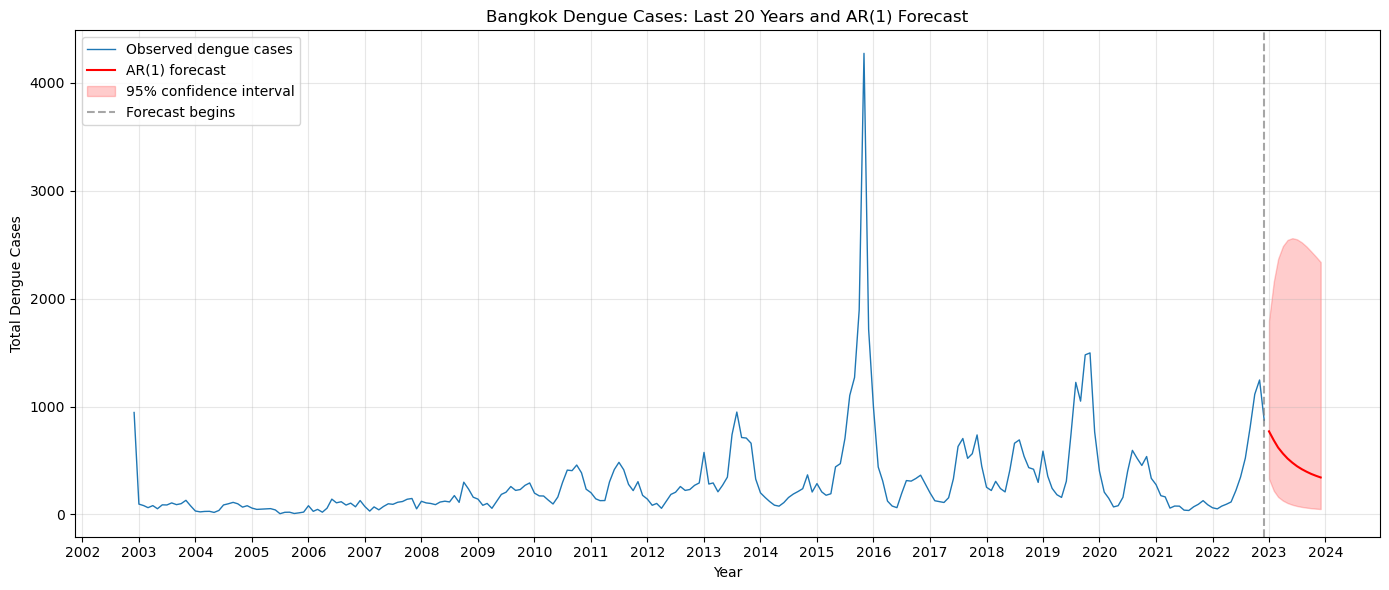

In [234]:
n_forecast = 12
forecast = ar1_model.get_forecast(steps=n_forecast)

# Predicted log cases and 95% confidence intervals
pred_log = forecast.predicted_mean
conf_log = forecast.conf_int(alpha=0.05)


# Transform back to the original case scale
pred = np.exp(pred_log)
lower = np.exp(conf_log.iloc[:, 0])
upper = np.exp(conf_log.iloc[:, 1])

# Create future monthly dates
last_date = df.loc[log_dengue.index, "calendar_start_date"].max()
future_dates = pd.date_range(
    start=last_date + pd.offsets.MonthBegin(1),
    periods=n_forecast,
    freq="MS"
)

# Show only the 10 years leading up to the forecast
forecast_start = future_dates[0]
plot_start = last_date - pd.DateOffset(years=20)

recent_df = df[
    (df["calendar_start_date"] >= plot_start)
    & (df["calendar_start_date"] <= last_date)
]

fig, ax = plt.subplots(figsize=(14, 6))

# Observed cases from the previous 10 years
ax.plot(
    recent_df["calendar_start_date"],
    recent_df["dengue_total"],
    label="Observed dengue cases",
    linewidth=1
)

# ARIMA predictions
ax.plot(
    future_dates,
    pred.values,
    color="red",
    label="AR(1) forecast"
)

# 95% confidence bands
ax.fill_between(
    future_dates,
    lower.values,
    upper.values,
    color="red",
    alpha=0.2,
    label="95% confidence interval"
)

# Mark forecast start
ax.axvline(
    last_date,
    color="gray",
    linestyle="--",
    alpha=0.7,
    label="Forecast begins"
)

ax.set_xlabel("Year")
ax.set_ylabel("Total Dengue Cases")
ax.set_title("Bangkok Dengue Cases: Last 20 Years and AR(1) Forecast")

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

The AR(1) model provides a somewhat interpolating forecast with conservative confidence intervals. 

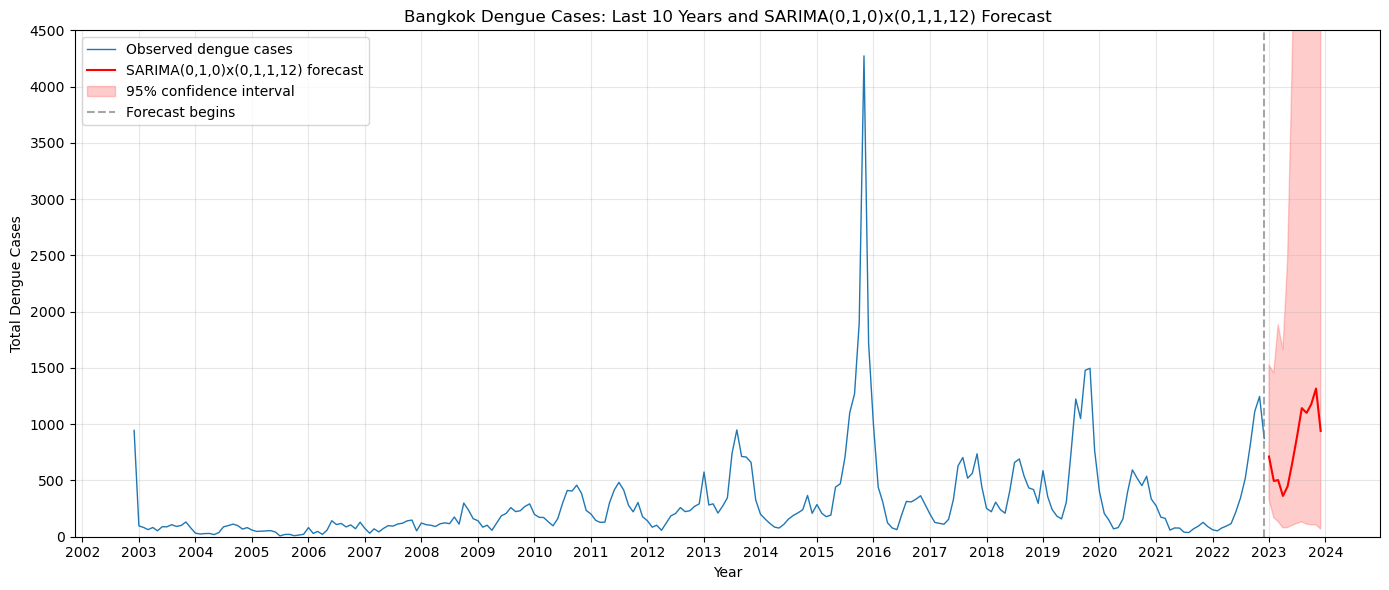

In [249]:
n_forecast = 12
forecast = sarima_model.get_forecast(steps=n_forecast)

# Predicted log cases and 95% confidence intervals
pred_log = forecast.predicted_mean
conf_log = forecast.conf_int(alpha=0.05)

# Transform back to the original case scale
pred = np.exp(pred_log)
lower = np.exp(conf_log.iloc[:, 0])
upper = np.exp(conf_log.iloc[:, 1])

# Create future monthly dates
last_date = df.loc[log_dengue.index, "calendar_start_date"].max()
future_dates = pd.date_range(
    start=last_date + pd.offsets.MonthBegin(1),
    periods=n_forecast,
    freq="MS"
)

# Show only the 10 years leading up to the forecast
forecast_start = future_dates[0]
plot_start = last_date - pd.DateOffset(years=20)

recent_df = df[
    (df["calendar_start_date"] >= plot_start)
    & (df["calendar_start_date"] <= last_date)
]

fig, ax = plt.subplots(figsize=(14, 6))

# Observed cases from the previous 10 years
ax.plot(
    recent_df["calendar_start_date"],
    recent_df["dengue_total"],
    label="Observed dengue cases",
    linewidth=1
)

# ARIMA predictions
ax.plot(
    future_dates,
    pred.values,
    color="red",
    label="SARIMA(0,1,0)x(0,1,1,12) forecast"
)

# 95% confidence bands
ax.fill_between(
    future_dates,
    lower.values,
    upper.values,
    color="red",
    alpha=0.2,
    label="95% confidence interval"
)

# Mark forecast start
ax.axvline(
    last_date,
    color="gray",
    linestyle="--",
    alpha=0.7,
    label="Forecast begins"
)

ax.set_xlabel("Year")
ax.set_ylabel("Total Dengue Cases")
ax.set_title("Bangkok Dengue Cases: Last 10 Years and SARIMA(0,1,0)x(0,1,1,12) Forecast")

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.set_ylim(0,4500)

ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

The SARIMA(0,1,0)x(0,1,1)_12 model provides a more interpolating forecast with less conservative confidence intervals. 